# Day 2 — one real BAO likelihood call
**Kernel:** `lecture-cloe` (NumPy 2; separate from cosmicfishpie).

We use the same public mock FITS inputs and construction as cloelike v0.3's BAO test. They are cached in `data/bao` for offline teaching. `cloelib` predicts the BAO dilation parameters; `cloelike` evaluates $-\chi^2/2$ using their covariance. This is a conditional $H_0$ scan, not a marginalised cosmological constraint.

Data: [Zenodo record 19729182](https://zenodo.org/records/19729182). Code: [cloe-org/cloelike](https://github.com/cloe-org/cloelike), `tests/test_EuclidLikelihood_GCspectro_BAO.py`.


In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import matplotlib.pyplot as plt
import requests
from euclidlib.le3.bao_gc import BAO_alphas, BAO_alphas_covariance
from cloelib.cosmology.camb_cosmology import CAMBBackground, CAMBLinearPerturbations
from cloelike.EuclidLikelihood_GCspectro_BAO import EuclidLikelihood_GCspectro_BAO
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'data').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'data').is_dir(), 'run this notebook from inside the bayes-cosmo-course repository'
CACHE = ROOT / 'data/bao'
CACHE.mkdir(parents=True, exist_ok=True)
labels = ['1.00', '1.20', '1.40', '1.65']
for label, remote in zip(labels, ['1.0', '1.2', '1.4', '1.65']):
    for short, long in [('bao', 'ALPHAS'), ('cov', 'COV')]:
        path = CACHE / f'{short}_z{label}.fits'
        if not path.exists():
            url = f'https://zenodo.org/records/19729182/files/EUC_LE3_BAO_{long}_Z{remote}.fits'
            response = requests.get(url, timeout=60)
            response.raise_for_status()
            path.write_bytes(response.content)
datavec = BAO_alphas(CACHE / 'bao_z{}.fits', *labels)
cov = BAO_alphas_covariance(CACHE / 'cov_z{}.fits', *labels)
data = {'GCspectro': {str(float(z)): {'datavec': datavec[('SPE','SPE',i,i)],
                                    'covariance': cov[('SPE','SPE',i,i)]}
                       for i,z in enumerate(labels)}}

## 1. Theory → likelihood
$\alpha_\perp=(D_M/r_d)/(D_M/r_d)_{\rm fid}$ and $\alpha_\parallel=(Hr_d)_{\rm fid}/(Hr_d)$.

The constructor needs both background and linear perturbation providers: it converts the mock's fiducial $\sigma_8$ to $A_s$. The short usage snippet in the package docs omits this required argument; the code below follows the tested API.


In [2]:
t0 = perf_counter()
like = EuclidLikelihood_GCspectro_BAO(data=data, Background=CAMBBackground,
                                     LinearPerturbations=CAMBLinearPerturbations)
parameters = dict(H0=67., Omega_cdm0=.27, Omega_b0=.049, ns=.96, As=2.1e-9,
                  alpha_s=0., w0=-1., wa=0., Omega_k0=0., mnu=0., gamma_MG=.545, N_mnu=0)
print('log L(fiducial):', like.loglike(parameters))
value = like.loglike(dict(parameters, H0=70.))
print('log L(H0=70):', value)
assert np.isclose(value, -1.93841, atol=5e-4)  # published repository regression check
setup_seconds = perf_counter() - t0


log L(fiducial): -0.0
log L(H0=70): -1.9384143839791665


## 2. Scan one parameter
Hold the density fractions and all other inputs fixed. Recompute the sound horizon as well as distances: this is not merely rescaling every distance by $H_0^{-1}$.


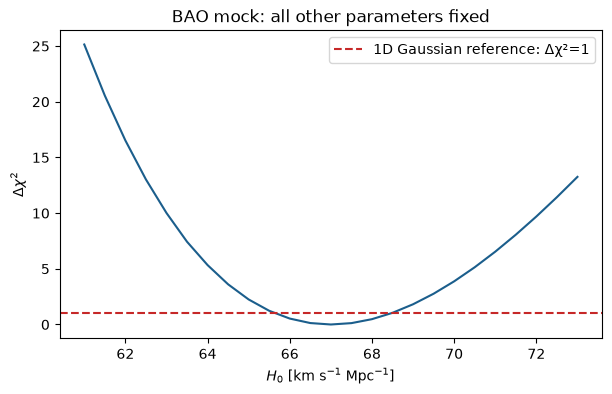

{'setup_seconds': 2.9925352100108285, 'scan_seconds': 0.5323734839912504}


In [3]:
t0 = perf_counter()
H0 = np.linspace(61, 73, 25)
logL = np.array([like.loglike(dict(parameters, H0=float(h))) for h in H0])
delta_chi2 = -2*(logL-logL.max())
assert np.isfinite(logL).all()
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(H0, delta_chi2, color='#1B5E8C')
ax.axhline(1, color='#C62828', ls='--', label='1D Gaussian reference: Δχ²=1')
ax.set(xlabel=r'$H_0$ [km s$^{-1}$ Mpc$^{-1}$]', ylabel=r'$\Delta\chi^2$',
       title='BAO mock: all other parameters fixed')
ax.legend(); plt.show()
out = ROOT / 'output'; out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / 'cloe_bao_scan.png', bbox_inches='tight')
timings = dict(setup_seconds=setup_seconds, scan_seconds=perf_counter()-t0)
(out / 'cloe_timings.json').write_text(json.dumps(timings, indent=2))
print(timings)
